# End-to-End Pipeline

## Preparation

In [1]:
%pip install -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [2]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import time
from sqlalchemy import create_engine
import plotly.express as px
import os

## Fetching data and understanding datastructure

In [3]:
BASE = "https://api.openbrewerydb.org/v1/breweries"
HEADERS = {"User-Agent": "brewery-notebook/1.0"}

# Fetch data from API
def extract(params, BASE=BASE, delay=0.3, per_page=200):
    frames, page = [], 1
    while True:
        r = requests.get(
            BASE,
            params={**params, "per_page": per_page, "page": page},
            headers=HEADERS,
            timeout=30,
        )
        r.raise_for_status()
        data = r.json()
        if not data:
            break
        frames.append(pd.DataFrame(data))
        page += 1
        time.sleep(delay)
    return pd.concat(frames, ignore_index=True)

engine = create_engine("sqlite:///brewery.sql")

try:
    df = extract({})
except requests.exceptions.RequestException as e:
    print("API unavailable, falling back to local sqlite:", e)
    df = pd.read_sql("SELECT * FROM brewery", con=engine)

# Filter for relevant data
print("---------BEFORE FILTERING---------")
print(df.info())

df = df[["brewery_type", "state_province", "country", "city", "phone"]]

print("---------AFTER FILTERING---------")
print(df.info())
print(df.head())

---------BEFORE FILTERING---------
<class 'pandas.DataFrame'>
RangeIndex: 11959 entries, 0 to 11958
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   id              11959 non-null  str    
 1   name            11959 non-null  str    
 2   brewery_type    11959 non-null  str    
 3   address_1       11205 non-null  str    
 4   address_2       331 non-null    object 
 5   address_3       40 non-null     object 
 6   city            11959 non-null  str    
 7   state_province  11959 non-null  str    
 8   postal_code     11957 non-null  str    
 9   country         11959 non-null  str    
 10  longitude       9491 non-null   float64
 11  latitude        9491 non-null   float64
 12  phone           10566 non-null  str    
 13  website_url     10622 non-null  str    
 14  state           11959 non-null  str    
 15  street          11205 non-null  str    
dtypes: float64(2), object(2), str(12)
memory usage: 1.5+

In [4]:
# Save data to sqlite file and test loading

df.to_sql(name="brewery", con=engine, if_exists="replace", index=False)

brewery_data = pd.read_sql("SELECT * FROM brewery", con=engine)
print(brewery_data.info())

<class 'pandas.DataFrame'>
RangeIndex: 11959 entries, 0 to 11958
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   brewery_type    11959 non-null  str  
 1   state_province  11959 non-null  str  
 2   country         11959 non-null  str  
 3   city            11959 non-null  str  
 4   phone           10566 non-null  str  
dtypes: str(5)
memory usage: 467.3 KB
None


### 1. Visualization

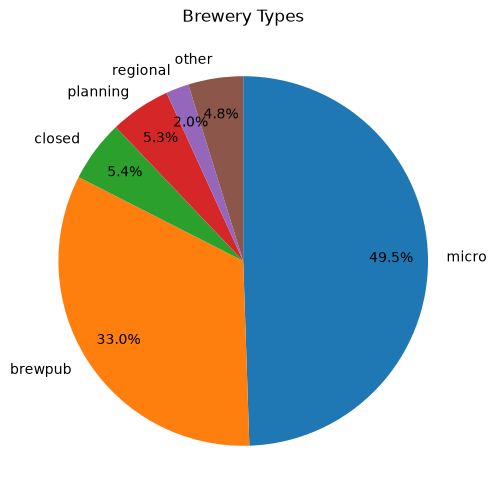

In [5]:
# Visualize the different brewery types as a pie chart

sql_command = '''
    SELECT brewery_type, COUNT(*) as n
    FROM brewery
    GROUP BY brewery_type
'''

brewery_types = pd.read_sql(sql_command, con=engine)
brewery_types = brewery_types.sort_values("n", ascending=False)

types = brewery_types["brewery_type"]
amounts = brewery_types["n"]
total = amounts.sum()

# Combine less represented types for the chart
small = brewery_types["n"] / total < 0.02
other = pd.DataFrame({"brewery_type": ["other"], "n": [brewery_types.loc[small, "n"].sum()]})
grouped = pd.concat([brewery_types[~small], other], ignore_index=True)

plt.figure(figsize=(6, 6))
plt.pie(grouped["n"], labels=grouped["brewery_type"], autopct="%1.1f%%", startangle=90, pctdistance=0.8, counterclock=False)

plt.title("Brewery Types")
plt.savefig("out/brewery_types.png")
plt.show()

## 1. Question: Which state in the USA has the most microbreweries

In [7]:
# Fetch microbreweries per us state

sql_command = '''
    SELECT state_province, country, brewery_type, COUNT(*) AS n
    FROM brewery
    WHERE country = 'United States'
      AND brewery_type = 'micro'
    GROUP BY state_province, country, brewery_type
    ORDER BY n DESC
    LIMIT 5
'''

micro_breweries_per_state = pd.read_sql(sql_command, con=engine)

# Get the state with the most microbreweries
top = micro_breweries_per_state.iloc[0]
state = top["state_province"]
amount = top["n"]

print("The state with the most micro breweries in the US is", state, "with", amount, "micro breweries")

The state with the most micro breweries in the US is California with 466 micro breweries


### Cross-Check

In [ ]:
# Fetching from the API again using the "meta" endpoint
BASE = "https://api.openbrewerydb.org/v1/breweries/meta"
r = requests.get(
    BASE,
    params={
        "by_country": "United States", "by_type":"micro"
    },
    headers=HEADERS,
    timeout=30,
)
r.raise_for_status()
data = r.json()

df_meta = pd.DataFrame([data])

by_state = pd.Series(data["by_state"]).astype(int)

top = by_state.sort_values(ascending=False).head(1)

state = top.index[0]
amount = top.iloc[0]

print("The state with the most micro breweries in the US is", state, "with", amount, "micro breweries")

## 2. Visualization

In [ ]:
# Visualize the distribution of breweries per state as a heatmap of the USA 

sql_command = '''
    SELECT state_province, country, COUNT(*) AS n
    FROM brewery
    WHERE country = 'United States'
    GROUP BY state_province, country
    ORDER BY n DESC
'''

breweries_per_state = pd.read_sql(sql_command, con=engine)

fig = px.choropleth(breweries_per_state,
                    locations='state_province', 
                    locationmode="USA-states", 
                    scope="usa",
                    color='n',
                    labels={"n": "Breweries"},
                    color_continuous_scale="Viridis_r", 
                    )
fig.update_layout(title_text="Breweries per State",
                  title_font_size=22,
                  title_x=0.45,
                  width=900, 
                  height=550
                  )
fig.write_image("out/breweries_per_state.png")
fig.show()

## 2. Question: What are the top 5 states in the USA with the most microbreweries?

In [ ]:
# Reusing the micro_breweries_per_state dataframe to get the top 5 states with the most microbreweries

top_5_states = micro_breweries_per_state.head(5)

print("The top 5 states in the USA with the most microbreweries are:")
count = 1
for state in top_5_states["state_province"]:
    print(count, state)
    count+=1

### 3. Visualization

In [ ]:
# Visualize these 5 states as a bar diagram with the amount of microbreweries they have

x = top_5_states["state_province"]
y = top_5_states["n"]

plt.bar(x, y)
plt.yticks(np.arange(0, 500, 50))
plt.xlabel("US State")
plt.ylabel("Brewery amount")
plt.title("Top 5 US States for microbreweries")
plt.tight_layout()

plt.savefig("out/top_five_us.png")

plt.show()

## 3. Question: How many brewpub breweries are there in the state or province of Incheon, South Korea?

In [ ]:
# Fetching the brewpubs based in Incheon from the DB

sql_command = '''
    SELECT state_province, brewery_type, COUNT(*) AS n
    FROM brewery
    WHERE state_province = 'Incheon'
      AND brewery_type = 'brewpub'
'''

brewpubs_incheon = pd.read_sql(sql_command, con=engine)
brewpubs_incheon_count = brewpubs_incheon.iloc[0]["n"]

print("There are", brewpubs_incheon_count, "brewpub breweries in Incheon, South Korea")

### Cross-Check

In [ ]:
# Alternative fetching from the APIs "meta" endpoint

BASE = "https://api.openbrewerydb.org/v1/breweries/meta"
r = requests.get(
    BASE,
    params={
        "by_country": "South Korea", "by_state": "Incheon", "by_type":"brewpub"
    },
    headers=HEADERS,
    timeout=30,
)
r.raise_for_status()
data = r.json()

brewpubs_incheon_count = data["total"]

print("There are", brewpubs_incheon_count, "brewpub breweries in Incheon, South Korea")

## 4. Question: How would you analyze the phone number patterns with cities in Korea based on the information given by the API?

In [ ]:
# Fetching the phone numbers in korean citys to check for common prefixes
# Only using the citys where at least two numbers are entered because otherwise no pattern can be found

sql_command = '''
    SELECT country, city, phone
    FROM brewery
    WHERE country = 'South Korea'
     AND phone IS NOT NULL 
'''

phones_korea = pd.read_sql(sql_command, con=engine)

numbers_by_city = phones_korea.groupby("city")["phone"].apply(list)

for city, phones in numbers_by_city.items():
    if len(phones) < 2:
        continue
    print(city, "\t", os.path.commonprefix(phones))